# CIC-IDS2017 특징 추출 설계
**캡스톤디자인 I** - 특징 추출 최적화 기반 암호화된 공격 트래픽 탐지 및 분류 시스템
팀장: 김강민 | 팀원: 서은빈

---
### 폴더 구조
```
capstone2026/output/
├── cleansing/
│   └── cicids2017_cleaned_v2.csv     ← 입력
└── features/
    └── CIC-IDS2017/                  ← 출력
        ├── cicids2017_corr_heatmap.png
        ├── cicids2017_feature_importance.png
        ├── cicids2017_features_final.csv
        └── cicids2017_selected_features.txt
```

## 0. Google Drive 마운트

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
BASE_DIR   = '/content/drive/MyDrive/capstone2026'
DATA_PATH  = os.path.join(BASE_DIR, 'output', 'cleansing', 'cicids2017_cleaned_v2.csv')
OUTPUT_DIR = os.path.join(BASE_DIR, 'output', 'features', 'CIC-IDS2017')
os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f'DATA_PATH : {DATA_PATH}')
print(f'OUTPUT_DIR: {OUTPUT_DIR}')

Mounted at /content/drive
DATA_PATH : /content/drive/MyDrive/capstone2026/output/cleansing/cicids2017_cleaned_v2.csv
OUTPUT_DIR: /content/drive/MyDrive/capstone2026/output/features/CIC-IDS2017


## 1. 폰트 설치 및 라이브러리 임포트

In [ ]:
import urllib.request
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder

# Noto Sans KR 다운로드 및 적용
font_url  = 'https://github.com/googlefonts/noto-cjk/raw/main/Sans/OTF/Korean/NotoSansCJKkr-Regular.otf'
font_path = '/content/NotoSansKR.otf'
urllib.request.urlretrieve(font_url, font_path)
fm.fontManager.addfont(font_path)
font_prop = fm.FontProperties(fname=font_path)
plt.rcParams['font.family'] = font_prop.get_name()
plt.rcParams['axes.unicode_minus'] = False

print('임포트 및 한글 폰트 설정 완료')

임포트 및 한글 폰트 설정 완료


## 2. 컬럼명 매핑 설정

In [ ]:
CIC_COL_MAP = {
    # 패킷 길이
    'Packet Length Variance':          'pkt_len_var',
    'Packet Length Mean':              'pkt_len_mean',
    'Packet Length Std':               'pkt_len_std',
    'Max Packet Length':               'pkt_len_max',
    'Min Packet Length':               'pkt_len_min',
    'Total Length of Fwd Packets':     'fwd_tot_len',
    'Total Length of Bwd Packets':     'bwd_tot_len',
    'Fwd Packet Length Max':           'fwd_pkt_len_max',
    'Fwd Packet Length Min':           'fwd_pkt_len_min',
    'Fwd Packet Length Mean':          'fwd_pkt_len_mean',
    'Fwd Packet Length Std':           'fwd_pkt_len_std',
    'Bwd Packet Length Max':           'bwd_pkt_len_max',
    'Bwd Packet Length Min':           'bwd_pkt_len_min',
    'Bwd Packet Length Mean':          'bwd_pkt_len_mean',
    'Bwd Packet Length Std':           'bwd_pkt_len_std',
    'Average Packet Size':             'avg_pkt_size',
    'Avg Fwd Segment Size':            'avg_fwd_seg',
    'Avg Bwd Segment Size':            'avg_bwd_seg',
    # 플로우
    'Flow Duration':                   'flow_dur',
    'Flow Bytes/s':                    'flow_bps',
    'Flow Packets/s':                  'flow_pps',
    'Flow IAT Max':                    'flow_iat_max',
    'Flow IAT Min':                    'flow_iat_min',
    'Flow IAT Mean':                   'flow_iat_mean',
    'Flow IAT Std':                    'flow_iat_std',
    # 패킷 수
    'Total Fwd Packets':               'fwd_tot_pkts',
    'Total Backward Packets':          'bwd_tot_pkts',
    'Bwd Packets/s':                   'bwd_pps',
    # IAT
    'Fwd IAT Min':                     'fwd_iat_min',
    'Fwd IAT Max':                     'fwd_iat_max',
    'Fwd IAT Mean':                    'fwd_iat_mean',
    'Fwd IAT Std':                     'fwd_iat_std',
    'Fwd IAT Total':                   'fwd_iat_tot',
    'Bwd IAT Min':                     'bwd_iat_min',
    'Bwd IAT Max':                     'bwd_iat_max',
    'Bwd IAT Mean':                    'bwd_iat_mean',
    'Bwd IAT Total':                   'bwd_iat_tot',
    # TCP
    'Init_Win_bytes_forward':          'init_win_fwd',
    'Init_Win_bytes_backward':         'init_win_bwd',
    'ACK Flag Count':                  'ack_cnt',
    'PSH Flag Count':                  'psh_cnt',
    'Fwd Header Length':               'fwd_hdr_len',
    'Bwd Header Length':               'bwd_hdr_len',
    'min_seg_size_forward':            'min_seg_fwd',
    'act_data_pkt_fwd':                'act_pkt_fwd',
    # Subflow
    'Subflow Fwd Bytes':               'subflow_fwd_bytes',
    'Subflow Bwd Bytes':               'subflow_bwd_bytes',
    'Subflow Fwd Packets':             'subflow_fwd_pkts',
    # Active/Idle
    'Active Max':                      'active_max',
    'Active Min':                      'active_min',
    'Active Mean':                     'active_mean',
    'Active Std':                      'active_std',
}
print(f'CIC 컬럼 매핑: {len(CIC_COL_MAP)}개')

CIC 컬럼 매핑: 52개


## 3. 데이터 로드

In [ ]:
df = pd.read_csv(DATA_PATH, encoding='utf-8-sig', low_memory=False)

for col in df.select_dtypes(include=['float64']).columns:
    df[col] = df[col].astype('float32')

print(f'로드 완료: {len(df):,}행 | {len(df.columns)}컬럼')
print(f'특징 수: {len(df.columns) - 1}개 (Label 제외)')

feature_cols = [c for c in df.columns if c != 'Label']
X = df[feature_cols]
y = df['Label']

로드 완료: 2,824,888행 | 69컬럼
특징 수: 68개 (Label 제외)


## 4. 상관관계 분석

In [ ]:
print('[상관관계 분석]')

corr_matrix = X.corr().abs()
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

threshold = 0.95
high_corr_pairs = []
to_drop_corr = set()

for col in upper.columns:
    high = upper[col][upper[col] > threshold]
    for idx, val in high.items():
        high_corr_pairs.append((idx, col, val))
        to_drop_corr.add(col)

print(f'  상관계수 > {threshold} 특징 쌍: {len(high_corr_pairs)}개')
print(f'  제거 대상: {len(to_drop_corr)}개')
for a, b, v in sorted(high_corr_pairs, key=lambda x: -x[2]):
    print(f'    {a} ↔ {b}: {v:.3f}')
print(f'  제거 후 잔여: {len(feature_cols) - len(to_drop_corr)}개')

[상관관계 분석]
  상관계수 > 0.95 특징 쌍: 57개
  제거 대상: 25개
    Fwd PSH Flags ↔ SYN Flag Count: 1.000
    Fwd URG Flags ↔ CWE Flag Count: 1.000
    Fwd Packet Length Mean ↔ Avg Fwd Segment Size: 1.000
    Bwd Packet Length Mean ↔ Avg Bwd Segment Size: 1.000
    Total Fwd Packets ↔ Subflow Fwd Packets: 1.000
    Total Backward Packets ↔ Subflow Bwd Packets: 1.000
    Total Length of Bwd Packets ↔ Subflow Bwd Bytes: 1.000
    Total Length of Fwd Packets ↔ Subflow Fwd Bytes: 1.000
    Flow Duration ↔ Fwd IAT Total: 0.999
    Flow IAT Max ↔ Fwd IAT Max: 0.998
    Packet Length Mean ↔ Average Packet Size: 0.998
    RST Flag Count ↔ ECE Flag Count: 0.998
    Total Backward Packets ↔ Bwd Header Length: 0.994
    Bwd Header Length ↔ Subflow Bwd Packets: 0.994
    Total Fwd Packets ↔ Total Backward Packets: 0.992
    Total Backward Packets ↔ Subflow Fwd Packets: 0.992
    Total Fwd Packets ↔ Subflow Bwd Packets: 0.992
    Subflow Fwd Packets ↔ Subflow Bwd Packets: 0.992
    Total Backward Packets ↔ Total Le

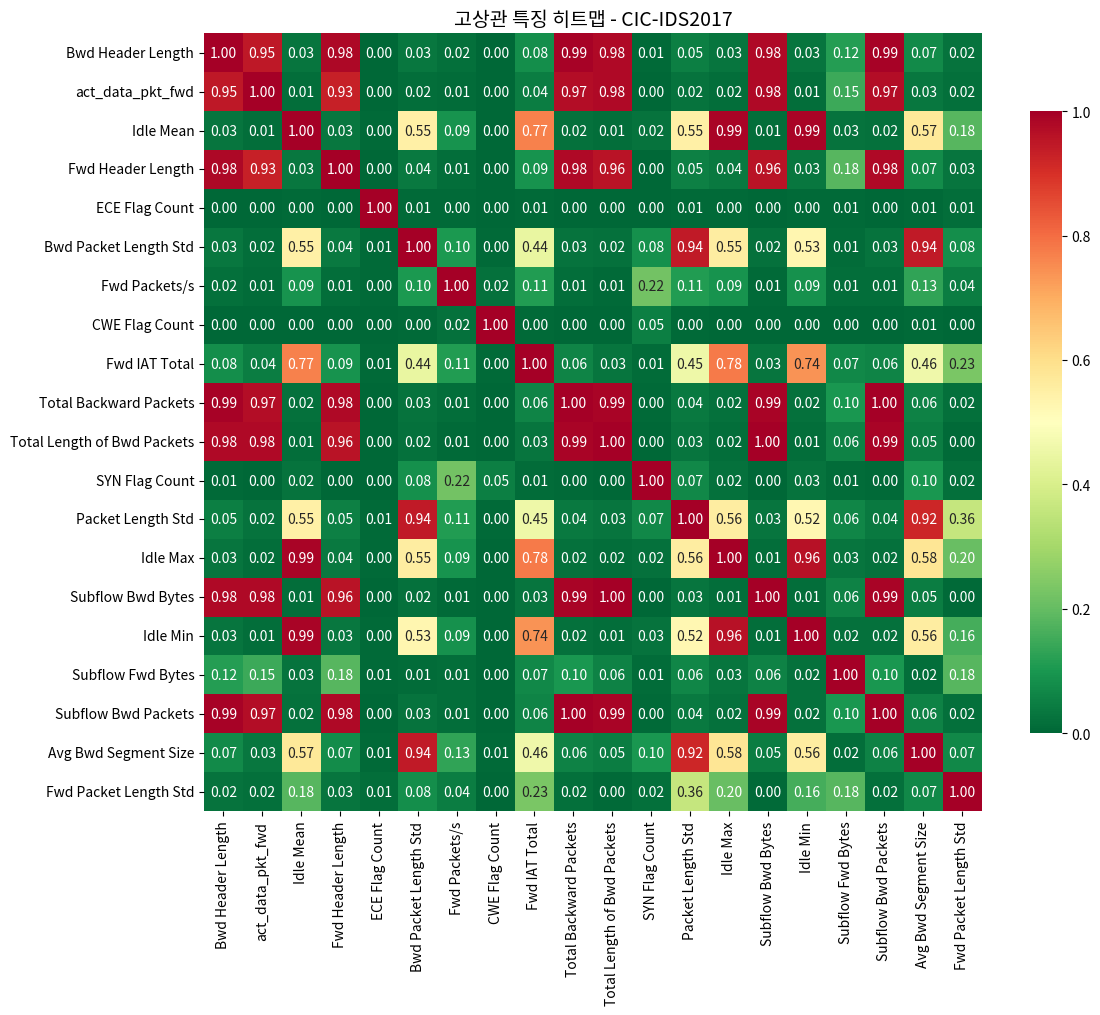

저장: /content/drive/MyDrive/capstone2026/output/features/CIC-IDS2017/cicids2017_corr_heatmap.png


In [ ]:
if to_drop_corr:
    drop_list = list(to_drop_corr)[:20]
    sub_corr = corr_matrix.loc[drop_list, drop_list]
    plt.figure(figsize=(12, 10))
    sns.heatmap(sub_corr, annot=True, fmt='.2f', cmap='RdYlGn_r',
                vmin=0, vmax=1, square=True, cbar_kws={'shrink': 0.8})
    plt.title('고상관 특징 히트맵 - CIC-IDS2017', fontsize=14)
    plt.tight_layout()
    save_path = os.path.join(OUTPUT_DIR, 'cicids2017_corr_heatmap.png')
    plt.savefig(save_path, dpi=150)
    plt.show()
    print(f'저장: {save_path}')

## 5. Random Forest 특징 중요도

In [ ]:
print('[RF 특징 중요도 - 10만 샘플]')

le = LabelEncoder()
y_enc = le.fit_transform(y)

sample_idx = np.random.choice(len(df), size=min(100000, len(df)), replace=False)
X_sample = X.iloc[sample_idx]
y_sample = y_enc[sample_idx]

rf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_sample, y_sample)

importances = pd.Series(rf.feature_importances_, index=feature_cols)
importances = importances.sort_values(ascending=False)

print('\n상위 20개:')
for feat, imp in importances.head(20).items():
    bar = '█' * int(imp * 500)
    print(f'  {feat:<40} {imp:.4f} {bar}')

[RF 특징 중요도 - 10만 샘플]

상위 20개:
  Avg Bwd Segment Size                     0.0610 ██████████████████████████████
  Bwd Packet Length Std                    0.0595 █████████████████████████████
  Average Packet Size                      0.0587 █████████████████████████████
  Bwd Packet Length Mean                   0.0494 ████████████████████████
  Packet Length Variance                   0.0470 ███████████████████████
  Subflow Fwd Bytes                        0.0456 ██████████████████████
  Packet Length Std                        0.0403 ████████████████████
  Total Length of Fwd Packets              0.0355 █████████████████
  Total Length of Bwd Packets              0.0320 ████████████████
  Bwd Packet Length Max                    0.0303 ███████████████
  Fwd Packet Length Max                    0.0291 ██████████████
  Subflow Bwd Bytes                        0.0275 █████████████
  Init_Win_bytes_forward                   0.0267 █████████████
  Packet Length Mean                      

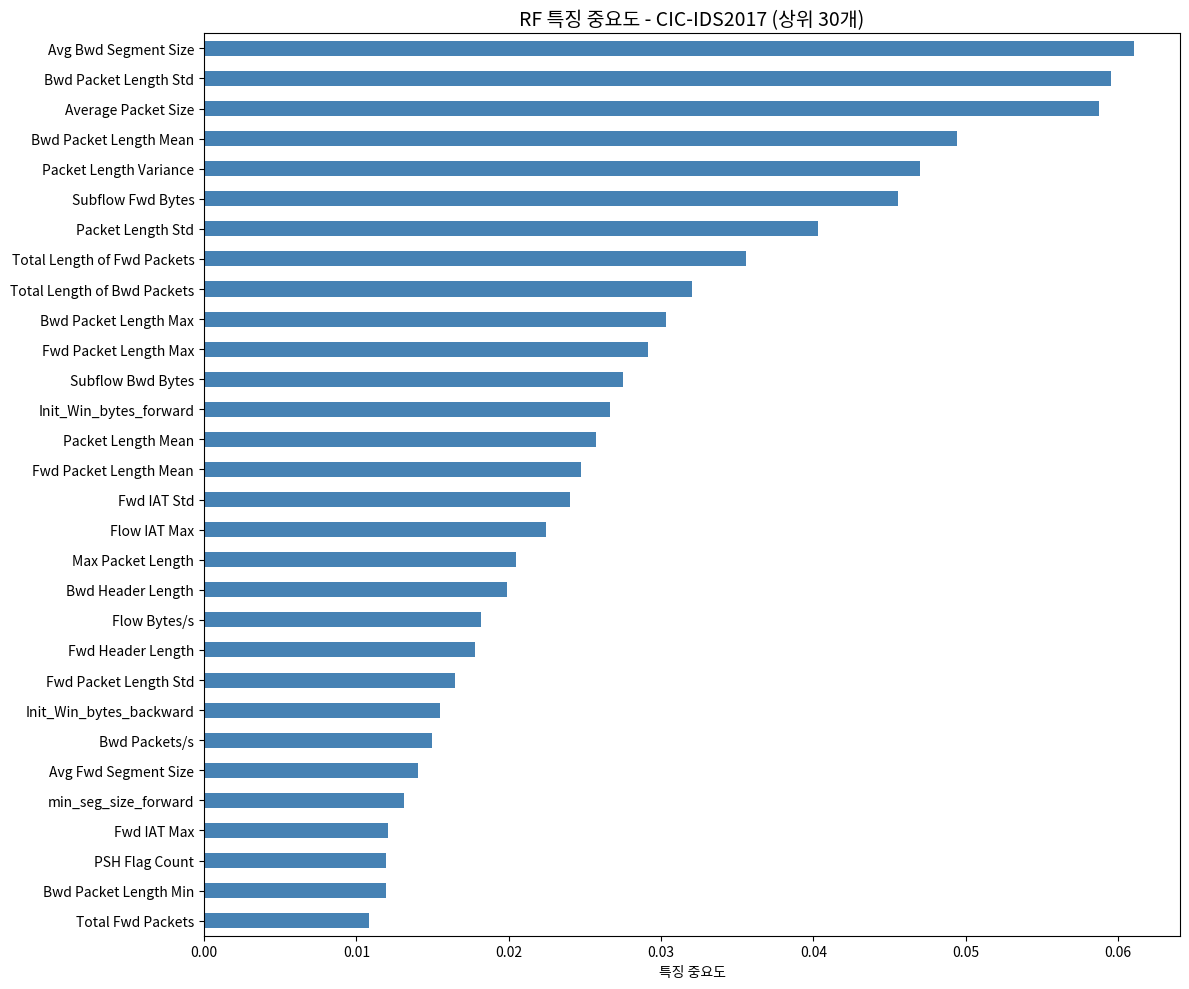

저장: /content/drive/MyDrive/capstone2026/output/features/CIC-IDS2017/cicids2017_feature_importance.png


In [ ]:
plt.figure(figsize=(12, 10))
importances.head(30).plot(kind='barh', color='steelblue')
plt.xlabel('특징 중요도')
plt.title('RF 특징 중요도 - CIC-IDS2017 (상위 30개)', fontsize=14)
plt.gca().invert_yaxis()
plt.tight_layout()
save_path = os.path.join(OUTPUT_DIR, 'cicids2017_feature_importance.png')
plt.savefig(save_path, dpi=150)
plt.show()
print(f'저장: {save_path}')

## 6. 최적 특징 셋 확정

In [ ]:
cumsum = importances.cumsum()
selected_by_importance = importances[cumsum <= 0.99].index.tolist()
final_features = [f for f in selected_by_importance if f not in to_drop_corr]

print('[최적 특징 셋 확정]')
print(f'  전체: {len(feature_cols)}개 → 상관관계 제거: {len(to_drop_corr)}개 → 최종: {len(final_features)}개')
print('\n최종 특징 목록:')
for i, f in enumerate(final_features, 1):
    abbr = CIC_COL_MAP.get(f, f)
    imp  = importances.get(f, 0)
    print(f'  {i:2d}. {f:<40} → {abbr:<25} ({imp:.4f})')

[최적 특징 셋 확정]
  전체: 68개 → 상관관계 제거: 25개 → 최종: 32개

최종 특징 목록:
   1. Packet Length Variance                   → pkt_len_var               (0.0470)
   2. Total Length of Fwd Packets              → fwd_tot_len               (0.0355)
   3. Bwd Packet Length Max                    → bwd_pkt_len_max           (0.0303)
   4. Fwd Packet Length Max                    → fwd_pkt_len_max           (0.0291)
   5. Init_Win_bytes_forward                   → init_win_fwd              (0.0267)
   6. Packet Length Mean                       → pkt_len_mean              (0.0257)
   7. Fwd Packet Length Mean                   → fwd_pkt_len_mean          (0.0247)
   8. Fwd IAT Std                              → fwd_iat_std               (0.0240)
   9. Flow IAT Max                             → flow_iat_max              (0.0224)
  10. Max Packet Length                        → pkt_len_max               (0.0205)
  11. Flow Bytes/s                             → flow_bps                  (0.0182)
  12. Init_Win_by

## 7. 컬럼명 약어화 및 저장

In [ ]:
# 최종 특징 셋 추출
df_final = df[final_features + ['Label']].copy()

# 컬럼명 약어화
df_final = df_final.rename(columns=CIC_COL_MAP)

# 변경된 최종 컬럼 목록
final_cols_renamed = [CIC_COL_MAP.get(f, f) for f in final_features]

print('[컬럼명 약어화 완료]')
print(f'  예시: Packet Length Variance → {CIC_COL_MAP.get("Packet Length Variance")}')
print(f'  최종 컬럼 수: {len(df_final.columns) - 1}개 (Label 제외)')

# 저장
out_path  = os.path.join(OUTPUT_DIR, 'cicids2017_features_final.csv')
feat_path = os.path.join(OUTPUT_DIR, 'cicids2017_selected_features.txt')

df_final.to_csv(out_path, index=False, encoding='utf-8-sig')
with open(feat_path, 'w') as f:
    for col in final_cols_renamed:
        f.write(col + '\n')

print(f'\n[저장 완료]')
print(f'  데이터  : {out_path}')
print(f'  특징목록: {feat_path}')
print(f'  최종    : {len(df_final):,}행 | {len(final_cols_renamed)}개 특징')
print(f'\n최종 컬럼 목록:')
print(final_cols_renamed)

[컬럼명 약어화 완료]
  예시: Packet Length Variance → pkt_len_var
  최종 컬럼 수: 32개 (Label 제외)

[저장 완료]
  데이터  : /content/drive/MyDrive/capstone2026/output/features/CIC-IDS2017/cicids2017_features_final.csv
  특징목록: /content/drive/MyDrive/capstone2026/output/features/CIC-IDS2017/cicids2017_selected_features.txt
  최종    : 2,824,888행 | 32개 특징

최종 컬럼 목록:
['pkt_len_var', 'fwd_tot_len', 'bwd_pkt_len_max', 'fwd_pkt_len_max', 'init_win_fwd', 'pkt_len_mean', 'fwd_pkt_len_mean', 'fwd_iat_std', 'flow_iat_max', 'pkt_len_max', 'flow_bps', 'init_win_bwd', 'bwd_pps', 'min_seg_fwd', 'psh_cnt', 'bwd_pkt_len_min', 'fwd_tot_pkts', 'flow_pps', 'flow_dur', 'flow_iat_std', 'ack_cnt', 'fwd_iat_mean', 'bwd_iat_tot', 'fwd_iat_min', 'flow_iat_mean', 'bwd_iat_mean', 'flow_iat_min', 'pkt_len_min', 'active_max', 'fwd_pkt_len_min', 'Down/Up Ratio', 'bwd_iat_max']
